# Ventanas: los trozos que verá el modelo

> 🧭 **En 30 segundos**
> - **Para qué:** cortar la señal en **ventanas de 4 s** (lo que verá el modelo) y apuntar a qué modelo pertenece cada una.
> - **Entra:** `senales.csv` + `senales/*.npy` → **Sale:** `ventanas.csv`: un índice (de qué `.npy` sale cada ventana y en qué muestra empieza), sin copiar la señal
> - **Idea clave:** una sola tabla sirve para todos los modelos (columnas `en_...`); las ventanas malas se marcan, no se borran.

> 📍 **Dónde estamos: Fase 2 · notebook 3 de 4.** `02_preprocesado` dejó la señal de cada tramo en un formato común (22 canales TCP, 256 Hz, filtrada, en µV). Este notebook la **corta en ventanas de 4 s**: los trozos que verá el modelo.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| **Fase 2** | **Preprocesado y ventanas** | 👉 **en curso** (la fase de este notebook) |
| Fase 3 | Modelo de predicción (◭ preictal frente a △ interictal) | pendiente |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## Qué hace este notebook

1. **Corta** cada tramo en ventanas de 4 s, con solape en ◭ preictal y ▲ ictal (sección 3).
2. Decide **a qué modelo pertenece** cada ventana preictal: modelo general, modelo de su grupo, comparación de umbrales y test común (sección 4).
3. **Mide la calidad** de cada ventana y **marca** las que se descartan, con un umbral **calculado con los datos** de las crisis de cada tipo (sección 5).
4. Cuenta las ventanas por clase y partición (sección 6) y las crisis que se quedan sin ventanas (sección 7).
5. Enseña una ventana de cada clase **tal y como la verá el modelo** (sección 8).

**No copia la señal.** Guarda un **índice** (`ventanas.csv`): de qué `.npy` sale cada ventana, en qué muestra empieza, su clase, a qué modelos pertenece y su calidad. En la Fase 3, el cargador leerá cada ventana directamente del `.npy` (sin cargar el fichero entero) y la **normalizará** en ese momento. Copiar las ventanas ocuparía más que la señal original, porque con solape cada muestra sale dos veces.

**Requisito**: haber ejecutado `02_preprocesado` (aunque sea en modo prueba: este notebook trabaja con los tramos que tengan señal guardada).

## Los notebooks de la Fase 2

| | Notebook | Qué hace | Entrada → salida | Estado |
|---|---|---|---|---|
| | `01_seleccion_crisis` | Elige qué señal se usa: tramos △ interictal, ◭ preictal y ▲ ictal. | Inventario → `tramos.csv` | ✅ |
| | `02_preprocesado` | Deja la señal en un formato común (TCP 22 canales, 256 Hz, filtrada, float16). | EDF → `senales/*.npy` + `senales.csv` | ✅ |
| 👉 | `03_ventanas` | **Corta en ventanas de 4 s**, decide a qué modelo pertenece cada una y marca las de mala calidad. | `senales.csv` → `ventanas.csv` | **este notebook** |
| | `04_particiones_y_balanceo` | Reparte por paciente y equilibra las clases solo en train (con un máximo de horas de interictal por paciente). | `ventanas.csv` → conjuntos para la Fase 3 | próximamente |

## 1. Importación de librerías

Las funciones de corte están en `tfm_comun/prediccion/ventanas.py`: trabajan con arrays de numpy, sin MNE, así que **sirven igual para la demo** (en directo se cortan ventanas de la señal que va llegando). La normalización viene de `tfm_comun/senal/normalizacion.py`.

In [1]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# tfm_comun está en ALMA, por encima de la carpeta de la fase: lo añadimos al path de Python
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from tqdm import tqdm
from IPython.display import display, Markdown

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_02, RUTA_SENALES
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.dataset.particiones import SPLITS
from tfm_comun.senal.montaje import CANALES_TCP, CANALES_FIGURAS
from tfm_comun.senal.remuestreo import FS_OBJETIVO
from tfm_comun.senal.senales import cargar_tramo
from tfm_comun.senal.calidad import UMBRAL_PLANO_UV
from tfm_comun.senal.normalizacion import NORMALIZACIONES
from tfm_comun.prediccion.umbrales import (UMBRAL_LEADIN_POR_DEFECTO_S, SPH_POR_DEFECTO_S,
                                           UMBRALES_LEADIN_COMPARACION_MIN)
from tfm_comun.prediccion.ventanas import (VENTANA_S, SOLAPE_POR_CLASE, DESDE_EL_FINAL, muestras_por_ventana,
                                           paso_en_muestras, inicios_ventanas, ventanas_de_senal,
                                           dentro_del_preictal)
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos
from tfm_comun.visual.colores import COLORES_SPLIT, COLORES_PERIODO, COLORES_ETIQUETA, COLOR_DESTACADO
from tfm_comun.visual.numeros import numero_legible, duracion_legible
from tfm_comun.visual.ejes import eje_log_legible
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero

versiones_usadas = mostrar_versiones(np, pd, matplotlib)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2


## Conceptos clave

- **Ventana**: un trozo de **4 s** de un tramo: una matriz de **22 canales × 1.024 muestras**. Es la unidad que el modelo clasifica. Hereda la clase de su tramo: △ `interictal`, ◭ `preictal` o ▲ `ictal`.
- **Por qué 4 s** (síntesis del estado del arte): las ausencias duran **~8,6 s** de media y con ventanas de 12 s o más se diluyen, así que se recomiendan **1–5 s**. En TUSZ se usan 1 s (Tang 2021), 2 s (Albaqami 2022 y 2023) y 5 s (Fan 2024); en predicción, 5 s (STAN 2025, Koutsouvelis 2024). 4 s cabe varias veces en los 50 s de preictal de las ausencias y son 1.024 muestras (potencia de 2, buena para la FFT). Se cambia en `ventanas.py`.
- **Solape**: cuánto comparte una ventana con la siguiente. △ interictal **sin solape** (sobra señal); ◭ preictal y ▲ ictal con **50 %** (hay poca: cada ventana empieza 2 s después de la anterior). No se inventa nada: son trozos reales desplazados.
- **A qué modelo pertenece**: una ventana ◭ preictal solo vale para un modelo si cae **entera** dentro de su preictal, entre *inicio de la crisis − umbral* y *inicio de la crisis − SPH*. Por eso cada ventana lleva varias columnas `en_...` (verdadero o falso). Las △ interictales valen para todos; las ▲ ictales, para la clasificación de tipos (Fase 4).
- **Rechazo**: una ventana se marca como descartada si tiene un pico de más de **1.000 µV** (solo en △ y ◭: a las crisis no se les aplica) o demasiados canales planos. El umbral es **el mismo para △ y ◭**: si cada clase se limpiara distinto, el modelo podría aprender a separarlas por el techo de amplitud y no por el EEG. Se **marca**, no se borra: en la Fase 3 se puede probar con y sin ellas.
- **Normalización**: no se hace aquí. La hace el cargador de la Fase 3 en cada ventana (`normalizacion.py`), igual que la hará la demo.

## 2. Configuración

| Parámetro | Valor | Qué controla |
|---|---|---|
| `UMBRAL_RECHAZO_UV` | 1.000 | Pico máximo (µV) de una ventana △/◭. Valor fijo, **el mismo para todas las clases y tipos**; en la sección 5 se comprueba con las crisis de cada tipo que no es demasiado bajo |
| `TIPOS_APARTE` | `['tcsz']` | Tipos que se espera que pasen del umbral (las tónico-clónicas tienen mucho músculo): no cuentan en la comprobación |
| `MAX_PERDIDA_PCT` | 5 | Aviso si △ o ◭ pierden más de este % por amplitud, o si un tipo (sin `TIPOS_APARTE`) tiene más de este % de ventanas ▲ por encima del umbral |
| `RECHAZO_EN_CLASES` | △ ◭ | Clases a las que se aplica el rechazo por amplitud. A ▲ ictal no, para no perder crisis |
| `MAX_CANALES_PLANOS` | 2 | Con más canales planos (electrodos sueltos) la ventana se descarta, sea de la clase que sea |
| `FICHERO_EJEMPLO` | `aaaaacrb_s001_t001` | La 🟩 ausencia de ejemplo, para las figuras |

El **tamaño de ventana** (4 s), el **solape** y el **umbral principal y los SPH** no se fijan aquí: vienen de `ventanas.py` y `umbrales.py`, para que la Fase 3 y la demo usen los mismos.

In [2]:
UMBRAL_RECHAZO_UV = 1000
TIPOS_APARTE = ['tcsz']
MAX_PERDIDA_PCT = 5
RECHAZO_EN_CLASES = ['interictal', 'preictal']
MAX_CANALES_PLANOS = 2
FICHERO_EJEMPLO = 'aaaaacrb_s001_t001'

In [3]:
# Rutas
RUTA_PREPROCESADO = RUTA_OUTPUTS_FASE_02 / '02_preprocesado'
RUTA_RESULTADOS = RUTA_OUTPUTS_FASE_02 / '03_ventanas'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Carga de senales.csv: solo los tramos con señal guardada (en modo prueba son pocos)
assert (RUTA_PREPROCESADO / 'senales.csv').exists(), \
    f'No encuentro {RUTA_PREPROCESADO / "senales.csv"}. Ejecuta antes fase_02/02_preprocesado.ipynb.'
senales_todas = pd.read_csv(RUTA_PREPROCESADO / 'senales.csv', dtype={'mascara_canales': str})   # texto, no número
tramos = senales_todas[senales_todas.n_muestras.notna()].copy()
tramos['n_muestras'] = tramos.n_muestras.astype(int)
modo_prueba = len(tramos) < len(senales_todas)
print(f'{numero_legible(len(tramos))} tramos con señal de {numero_legible(len(senales_todas))} '
      f'({numero_legible(tramos.file.nunique())} ficheros)' + ('  ·  ⚠️ MODO PRUEBA: el preprocesado no está completo' if modo_prueba else ''))

UMBRAL_PRINCIPAL_MIN = UMBRAL_LEADIN_POR_DEFECTO_S // 60
TAMANO = muestras_por_ventana()
config = {
    'senales': str(RUTA_PREPROCESADO / 'senales.csv'),
    'tramos_con_senal': int(len(tramos)),
    'modo_prueba': bool(modo_prueba),
    'ventana_s': VENTANA_S,
    'muestras_por_ventana': TAMANO,
    'solape_por_clase': SOLAPE_POR_CLASE,
    'preictal_desde_el_final': DESDE_EL_FINAL['preictal'],
    'umbral_principal_min': UMBRAL_PRINCIPAL_MIN,
    'sph_general_s': SPH_POR_DEFECTO_S,
    'umbrales_comparacion_min': UMBRALES_LEADIN_COMPARACION_MIN,
    'umbral_rechazo_uv': UMBRAL_RECHAZO_UV,
    'tipos_aparte': TIPOS_APARTE,
    'max_perdida_pct': MAX_PERDIDA_PCT,
    'rechazo_en_clases': RECHAZO_EN_CLASES,
    'max_canales_planos': MAX_CANALES_PLANOS,
    'umbral_canal_plano_uv': UMBRAL_PLANO_UV,
    'fichero_ejemplo': FICHERO_EJEMPLO,
    'versiones': versiones_usadas,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json',
                'parámetros del corte en ventanas (tamaño, solape, umbrales de los modelos y criterios de rechazo), las versiones y la fecha')

103 tramos con señal de 7.665 (20 ficheros)  ·  ⚠️ MODO PRUEBA: el preprocesado no está completo


💾 **Guardado `configuracion.json`** · 1 KB · 19 claves  
*Qué guarda:* parámetros del corte en ventanas (tamaño, solape, umbrales de los modelos y criterios de rechazo), las versiones y la fecha. *Abajo:* todas las claves (son pocas).

,valor
clave,
senales,D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_02\02_preprocesado\senales.csv
tramos_con_senal,103
modo_prueba,true
ventana_s,4
muestras_por_ventana,1024
solape_por_clase,"{""interictal"": 0.0, ""preictal"": 0.5, ""ictal"": 0.5}"
preictal_desde_el_final,true
umbral_principal_min,4
sph_general_s,60


## 3. Cortar los tramos en ventanas

Para cada tramo se calcula dónde empieza cada ventana (`inicios_ventanas`) y, de paso, **su calidad**, que hace falta leer la señal para medirla:

- `amplitud_max_uv`: el pico más alto de la ventana, en µV, en los canales válidos.
- `canales_planos`: canales válidos casi quietos (desviación < 0,5 µV): electrodo suelto o apagado.

Cada ventana guarda **dónde está** (`ruta` del `.npy` y `muestra_inicio`) y **cuándo es** dentro del EDF (`inicio_s` y `fin_s`). Las ◭ preictales se cortan **desde el final** del tramo, para que la última termine justo donde empieza el SPH.

Tarda unos minutos con todos los datos: lee una vez los ~36 GB de señal.

In [4]:
filas = []
inicio_corte = time.time()
for t in tqdm(tramos.itertuples(), total=len(tramos), desc='Tramos', unit='tramo'):
    paso = paso_en_muestras(t.clase)
    inicios = inicios_ventanas(t.n_muestras, TAMANO, paso, desde_el_final=DESDE_EL_FINAL[t.clase])
    if len(inicios) == 0:
        continue                                       # tramo más corto que una ventana (crisis muy cortas)
    validos = np.array([c == '1' for c in str(t.mascara_canales).zfill(len(CANALES_TCP))])
    senal = cargar_tramo(RUTA_SENALES / t.ruta)          # mmap: solo se lee lo que se usa
    ventanas = ventanas_de_senal(senal, TAMANO, inicios)[:, validos, :].astype(np.float32)   # (ventanas, canales, muestras)
    amplitud = np.abs(ventanas).max(axis=(1, 2))
    planos = (ventanas.std(axis=2) < UMBRAL_PLANO_UV).sum(axis=1)
    for inicio, amp, n_planos in zip(inicios, amplitud, planos):
        filas.append((t.id_tramo, inicio, amp, n_planos))

ventanas_df = pd.DataFrame(filas, columns=['id_tramo', 'muestra_inicio', 'amplitud_max_uv', 'canales_planos'])
COLUMNAS_TRAMO = ['id_tramo', 'clase', 'split', 'patient', 'file', 'ruta', 'tipo', 'grupo', 'crisis_id', 'inicio_s',
                  'inicio_crisis_s', 'umbral_tipo_s', 'sph_tipo_s', 'cumple_umbral_tipo', 'test_comun',
                  *[f'cumple_{u}min' for u in UMBRALES_LEADIN_COMPARACION_MIN]]
ventanas_df = ventanas_df.merge(tramos[COLUMNAS_TRAMO].rename(columns={'inicio_s': 'inicio_tramo_s'}), on='id_tramo')
ventanas_df['inicio_s'] = (ventanas_df.inicio_tramo_s + ventanas_df.muestra_inicio / FS_OBJETIVO).round(3)
ventanas_df['fin_s'] = (ventanas_df.inicio_s + VENTANA_S).round(3)
ventanas_df['segundos_hasta_crisis'] = np.where(ventanas_df.clase == 'preictal',
                                                (ventanas_df.inicio_crisis_s - ventanas_df.fin_s).round(2), np.nan)
print(f'{numero_legible(len(ventanas_df))} ventanas de {numero_legible(ventanas_df.id_tramo.nunique())} tramos '
      f'en {(time.time() - inicio_corte) / 60:.1f} min')
display(tabla_con_iconos(ventanas_df.groupby(['clase', 'split']).size().unstack().reindex(columns=SPLITS).fillna(0).astype(int)))

Tramos: 100%|██████████| 103/103 [00:01<00:00, 55.27tramo/s]

6.579 ventanas de 99 tramos en 0.0 min


split,🔵 train,🟡 dev,🟢 eval
clase,,,
▲ ictal,422,136,94
△ interictal,1288,265,309
◭ preictal,2783,716,566


👀 **Cómo leer la tabla.** Ventanas cortadas por clase y partición, **antes** de asignarlas a modelos. Salen muchas ◭ porque se corta el tramo preictal **más largo** y con 50 % de solape; en la sección 4 se quitan las que no caen en el preictal de ningún modelo.

## 4. A qué modelo pertenece cada ventana

Una misma ventana ◭ preictal puede valer para un modelo y no para otro, porque cada modelo tiene su **umbral** (cuánto preictal hace falta) y su **SPH** (cuánto se deja libre antes de la crisis). Se añade una columna por modelo, verdadero si la ventana cae **entera** dentro de su preictal (`dentro_del_preictal`) y la crisis supera su umbral:

| Columna | Modelo | Preictal: de … a … antes de la crisis |
|---|---|---|
| `en_general` | Modelo general (Fase 3) | de 4 min a 1 min |
| `en_umbral_<U>min` | Comparación de umbrales | de U min a 1 min |
| `en_modelo_grupo` | Modelo de su grupo de inicio | de su umbral a su SPH (`umbrales.py`; ausencias: de 60 s a 10 s) |
| `en_test_comun` | Test común entre umbrales (solo 🟢 eval) | de 2 min a 1 min |
| `en_clasificacion` | Clasificación de tipos (Fase 4) | ▲ ventanas ictales |

Las △ interictales valen para **todos** los modelos de predicción (`04` se queda solo con las de los pacientes de cada modelo). Las ◭ preictales que **no entran en ningún modelo** (por ejemplo, las que están a más de 15 min de la crisis) se quitan.

La figura muestra el corte en una crisis real: cada rectángulo es una ventana de 4 s, y cada fila, un modelo.

In [5]:
pre = ventanas_df.clase == 'preictal'
inter = ventanas_df.clase == 'interictal'
def dentro(umbral_s, sph_s):
    return dentro_del_preictal(ventanas_df.inicio_s, ventanas_df.fin_s, ventanas_df.inicio_crisis_s, umbral_s, sph_s)

ventanas_df['en_general'] = inter | (pre & ventanas_df[f'cumple_{UMBRAL_PRINCIPAL_MIN}min'].fillna(False).astype(bool)
                                     & dentro(UMBRAL_LEADIN_POR_DEFECTO_S, SPH_POR_DEFECTO_S))
for u in UMBRALES_LEADIN_COMPARACION_MIN:
    ventanas_df[f'en_umbral_{u}min'] = inter | (pre & ventanas_df[f'cumple_{u}min'].fillna(False).astype(bool)
                                                & dentro(u * 60, SPH_POR_DEFECTO_S))
ventanas_df['en_modelo_grupo'] = inter | (pre & ventanas_df.cumple_umbral_tipo.fillna(False).astype(bool)
                                          & dentro(ventanas_df.umbral_tipo_s, ventanas_df.sph_tipo_s))
ventanas_df['en_test_comun'] = (inter & (ventanas_df.split == 'eval')) | \
                               (pre & ventanas_df.test_comun.fillna(False).astype(bool)
                                & dentro(min(UMBRALES_LEADIN_COMPARACION_MIN) * 60, SPH_POR_DEFECTO_S))
ventanas_df['en_clasificacion'] = ventanas_df.clase == 'ictal'

COLUMNAS_MODELO = ['en_general', *[f'en_umbral_{u}min' for u in UMBRALES_LEADIN_COMPARACION_MIN],
                   'en_modelo_grupo', 'en_test_comun', 'en_clasificacion']
sin_modelo = pre & ~ventanas_df[COLUMNAS_MODELO].any(axis=1)
print(f'◭ Ventanas preictales que no entran en ningún modelo (se quitan): {numero_legible(int(sin_modelo.sum()))} '
      f'de {numero_legible(int(pre.sum()))}')
ventanas_sin_modelo = ventanas_df[sin_modelo]                     # se guardan para la figura
ventanas_df = ventanas_df[~sin_modelo].reset_index(drop=True)

# Ventanas ◭ preictales de cada modelo, por partición
por_modelo = pd.DataFrame({c: ventanas_df[ventanas_df.clase == 'preictal'].groupby('split')[c].sum()
                           for c in COLUMNAS_MODELO if c != 'en_clasificacion'}).T.reindex(columns=SPLITS).fillna(0).astype(int)
por_modelo.index.name = '◭ ventanas preictales de…'
display(tabla_con_iconos(por_modelo))

◭ Ventanas preictales que no entran en ningún modelo (se quitan): 922 de 4.065


split,🔵 train,🟡 dev,🟢 eval
◭ ventanas preictales de…,,,
en_general,705,88,176
en_umbral_2min,561,140,84
en_umbral_3min,755,116,116
en_umbral_4min,705,88,176
en_umbral_5min,827,118,236
en_umbral_7min,712,178,356
en_umbral_10min,804,0,268
en_umbral_15min,0,0,0
en_modelo_grupo,759,295,176


👀 **Cómo leer la tabla.** Una fila por modelo y una columna por partición: cuántas ventanas ◭ preictales valen para ese modelo. Una misma ventana puede contar en varias filas (por ejemplo, en el modelo general y en el de 5 min).

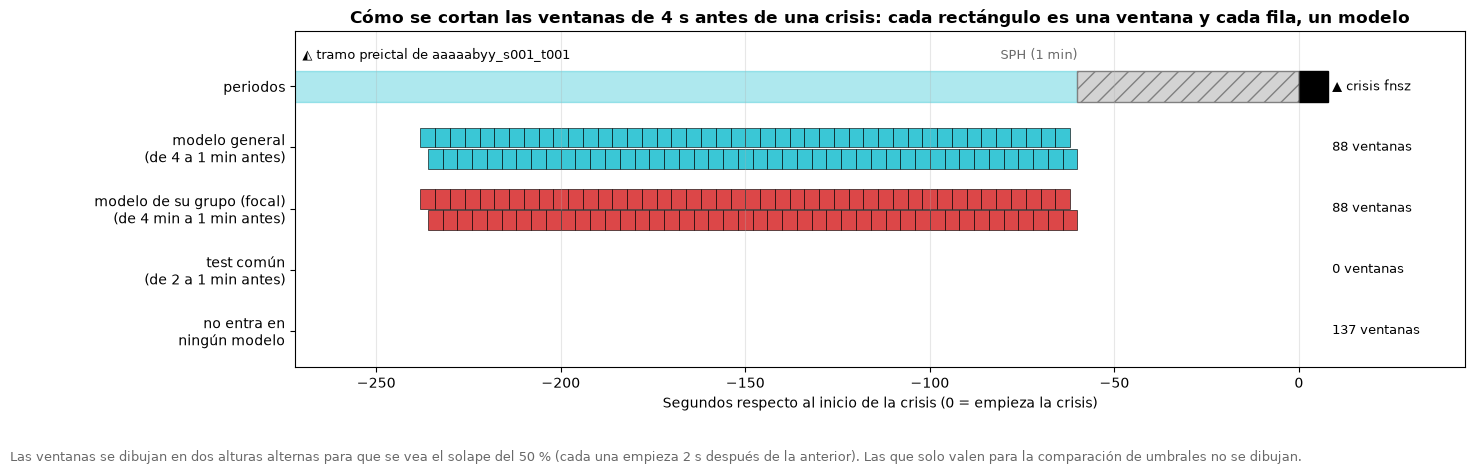

In [6]:
# Figura: cómo se cortan las ventanas antes de una crisis real
preictales = tramos[tramos.clase == 'preictal']
candidatos = preictales[preictales.file == FICHERO_EJEMPLO]
if candidatos.empty:
    candidatos = preictales
tramo_fig = candidatos.loc[candidatos.duracion_s.idxmax()] if not candidatos.empty else None

if tramo_fig is not None:
    v = pd.concat([ventanas_df[ventanas_df.id_tramo == tramo_fig.id_tramo],
                   ventanas_sin_modelo[ventanas_sin_modelo.id_tramo == tramo_fig.id_tramo]])
    crisis_t = tramo_fig.inicio_crisis_s
    filas_fig = [('modelo general\n(de 4 a 1 min antes)', 'en_general', COLORES_PERIODO['preictal']),
                 (f'modelo de su grupo ({tramo_fig.grupo})\n(de {duracion_legible(tramo_fig.umbral_tipo_s)} a {duracion_legible(tramo_fig.sph_tipo_s)} antes)',
                  'en_modelo_grupo', COLORES_ETIQUETA.get(tramo_fig.tipo, 'black')),
                 ('test común\n(de 2 a 1 min antes)', 'en_test_comun', COLORES_SPLIT['eval']),
                 ('no entra en\nningún modelo', None, 'lightgray')]
    fig, ax = plt.subplots(figsize=(15, 4.8))
    x0 = tramo_fig.inicio_s - crisis_t
    ax.add_patch(Rectangle((x0, 4.15), -x0 - tramo_fig.sph_tipo_s, 0.5, color=COLORES_PERIODO['preictal'], alpha=0.35))
    ax.add_patch(Rectangle((-tramo_fig.sph_tipo_s, 4.15), tramo_fig.sph_tipo_s, 0.5, facecolor=COLORES_PERIODO['margen'],
                           hatch='//', edgecolor='gray'))
    ax.add_patch(Rectangle((0, 4.15), 8, 0.5, color=COLORES_PERIODO['ictal']))
    izquierda = max(x0, -(max(UMBRAL_LEADIN_POR_DEFECTO_S, tramo_fig.umbral_tipo_s, 120) + 30))
    ax.text(izquierda, 4.8, f'◭ tramo preictal de {tramo_fig.file}', fontsize=9, va='bottom')
    ax.text(-tramo_fig.sph_tipo_s, 4.8, f'SPH ({duracion_legible(tramo_fig.sph_tipo_s)})', ha='right', fontsize=9,
            va='bottom', color='dimgray')
    ax.text(9, 4.4, f'▲ crisis {tramo_fig.tipo}', ha='left', fontsize=9, va='center')
    for fila, (_, columna, color) in enumerate(filas_fig):
        y = 3 - fila
        elegidas = v[v[columna]] if columna else v[~v[COLUMNAS_MODELO].any(axis=1)]
        for k, w in enumerate(elegidas.sort_values('inicio_s').itertuples()):
            ax.add_patch(Rectangle((w.inicio_s - crisis_t, y + (0.05 if k % 2 else 0.4)), VENTANA_S, 0.32,
                                   facecolor=color, edgecolor='black', lw=0.5, alpha=0.85))
        ax.text(9, y + 0.4, f'{len(elegidas)} ventanas', fontsize=9, va='center')
    ax.set_yticks([3.4 - k for k in range(len(filas_fig))] + [4.4],
                  [nombre for nombre, _, _ in filas_fig] + ['periodos'])
    ax.set_xlim(izquierda - 2, 45)
    ax.set_ylim(-0.2, 5.3)
    ax.set_xlabel('Segundos respecto al inicio de la crisis (0 = empieza la crisis)')
    ax.set_title(f'Cómo se cortan las ventanas de {VENTANA_S} s antes de una crisis: cada rectángulo es una ventana y '
                 'cada fila, un modelo', fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    fig.text(0.01, 0.005, 'Las ventanas se dibujan en dos alturas alternas para que se vea el solape del 50 % '
             '(cada una empieza 2 s después de la anterior). Las que solo valen para la comparación de umbrales no se dibujan.', fontsize=9, color='dimgray')
    fig.subplots_adjust(left=0.2, right=0.98, top=0.9, bottom=0.2)
    fig.savefig(RUTA_FIGURAS / 'corte_ventanas.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Eje X: segundos hasta la crisis (0 = inicio de la crisis). La barra de arriba es el tramo preictal, el SPH (rayado) y la crisis. Debajo, una fila por modelo: cada rectángulo es una ventana de 4 s que **sí** vale para ese modelo; la fila gris, las que no valen para ninguno y se quitan.

## 5. Calidad: qué ventanas se descartan

El umbral de rechazo por amplitud es un **valor fijo de 1.000 µV**, el mismo para △ interictal y ◭ preictal:

1. **Por qué uno común y no por tipo de crisis.** Las △ no tienen tipo, y si △ y ◭ se limpiaran con umbrales distintos el modelo podría aprender a separarlas por el techo de amplitud (un atajo), no por el EEG. Que cada tipo de crisis llegue a amplitudes distintas importa para **clasificarlas** (Fase 4), no para decidir qué es un artefacto.
2. **Por qué fijo y no el p99 de las crisis.** Las ventanas ▲ que más alto llegan son justo las más contaminadas (movimiento, músculo), así que su p99 sale inflado: en una ejecución de prueba daba ~3.900 µV con 🟦 `gnsz` (🔷) y casi no limpiaba nada. Tras el filtrado, más de 1.000 µV es casi seguro artefacto.
3. **Se comprueba con los datos**: la tabla dice, por tipo, qué % de sus ventanas ▲ quedan por encima. Si un tipo (sin contar 🟪 `tcsz` (🔷)) pasa de `MAX_PERDIDA_PCT`, o △ ◭ pierden más de eso, sale un aviso y conviene subir el umbral.
4. **A las ▲ crisis no se les aplica**, para no perder ninguna.

Además, se descarta cualquier ventana con más de `MAX_CANALES_PLANOS` canales planos.

Las ventanas descartadas **no se borran**: llevan `rechazada = True` y el `motivo_rechazo`.


In [7]:
ictales = ventanas_df[ventanas_df.clase == 'ictal']
umbral_rechazo = float(UMBRAL_RECHAZO_UV)
origen_umbral = 'valor fijo, común a △ y ◭, comprobado con las crisis de cada tipo'
umbral_por_tipo = ictales.groupby('tipo').agg(
    crisis=('crisis_id', 'nunique'), ventanas=('amplitud_max_uv', 'size'),
    mediana_uv=('amplitud_max_uv', 'median'),
    p95_uv=('amplitud_max_uv', lambda a: a.quantile(0.95)),
    p99_uv=('amplitud_max_uv', lambda a: a.quantile(0.99)),
    maximo_uv=('amplitud_max_uv', 'max'),
    pct_por_encima=('amplitud_max_uv', lambda a: (a > umbral_rechazo).mean() * 100)).sort_values('crisis', ascending=False)
umbral_por_tipo['cuenta_en_la_comprobacion'] = ~umbral_por_tipo.index.isin(TIPOS_APARTE)

umbral_por_tipo.round(1).to_csv(RUTA_RESULTADOS / 'umbral_rechazo_por_tipo.csv', index_label='tipo')
mostrar_fichero(RUTA_RESULTADOS / 'umbral_rechazo_por_tipo.csv',
                'una fila por tipo de crisis: cuántas crisis y ventanas ▲ ictales tiene, lo alto que llegan (mediana, p95, p99 y máximo, en µV), '
                'qué % de sus ventanas quedan por encima del umbral (pct_por_encima) y si cuenta en la comprobación')

por_amplitud = ventanas_df.clase.isin(RECHAZO_EN_CLASES) & (ventanas_df.amplitud_max_uv > umbral_rechazo)
por_planos = ventanas_df.canales_planos > MAX_CANALES_PLANOS
ventanas_df['rechazada'] = por_amplitud | por_planos
ventanas_df['motivo_rechazo'] = np.select([por_amplitud & por_planos, por_amplitud, por_planos],
                                          ['amplitud y canales planos', 'amplitud', 'canales planos'], default='')
display(Markdown(f'**Umbral de rechazo: {numero_legible(round(umbral_rechazo))} µV** ({origen_umbral}).'))

# Comprobación: el umbral no debe ser demasiado bajo
tipos_altos = umbral_por_tipo[umbral_por_tipo.cuenta_en_la_comprobacion & (umbral_por_tipo.pct_por_encima > MAX_PERDIDA_PCT)]
perdida_amplitud = (por_amplitud.groupby(ventanas_df.clase).mean() * 100).reindex(RECHAZO_EN_CLASES)
for tipo, fila in tipos_altos.iterrows():
    print(f'🔴 {con_icono(tipo)}: {fila.pct_por_encima:.1f} % de sus ventanas ▲ superan el umbral (más de {MAX_PERDIDA_PCT} %): plantéate subirlo')
for clase, pct in perdida_amplitud.items():
    print(f'{"🔴" if pct > MAX_PERDIDA_PCT else "✅"} {con_icono(clase)}: {pct:.1f} % de las ventanas se descartan por amplitud')
if tipos_altos.empty:
    print(f'✅ Ningún tipo de crisis (sin contar {", ".join(TIPOS_APARTE)}) tiene más de un {MAX_PERDIDA_PCT} % de ventanas por encima del umbral')


💾 **Guardado `umbral_rechazo_por_tipo.csv`** · 333 B · 5 filas × 9 columnas  
*Qué guarda:* una fila por tipo de crisis: cuántas crisis y ventanas ▲ ictales tiene, lo alto que llegan (mediana, p95, p99 y máximo, en µV), qué % de sus ventanas quedan por encima del umbral (pct_por_encima) y si cuenta en la comprobación. *Abajo:* las 5 primeras filas.

,tipo,crisis,ventanas,mediana_uv,p95_uv,p99_uv,maximo_uv,pct_por_encima,cuenta_en_la_comprobacion
0,🟩 absz (🔹),23,101,492.0,578.0,579.5,637.5,0.0,True
1,🟦 gnsz (🔷),14,168,100.9,1052.0,3900.3,5188.0,6.5,True
2,🟥 fnsz (♦️),11,324,96.3,212.7,1610.0,1780.0,1.5,True
3,🟧 cpsz (♦️),2,38,58.8,668.3,715.5,715.5,0.0,True
4,🟪 tcsz (🔷),1,21,1012.5,4328.0,4328.0,4328.0,61.9,False


**Umbral de rechazo: 1.000 µV** (valor fijo, común a △ y ◭, comprobado con las crisis de cada tipo).

🔴 🟦 gnsz (🔷): 6.5 % de sus ventanas ▲ superan el umbral (más de 5 %): plantéate subirlo
🔴 △ interictal: 17.3 % de las ventanas se descartan por amplitud
✅ ◭ preictal: 1.3 % de las ventanas se descartan por amplitud


👀 **Cómo leer los avisos.** ✅ = dentro de lo aceptable; 🔴 = se pierde más de `MAX_PERDIDA_PCT`. Si un 🔴 sale en un tipo de crisis, el umbral se le queda corto a ese tipo; si sale en △ o ◭, se están tirando muchas ventanas. **En modo prueba los porcentajes no son representativos**: el umbral se valida con el preprocesado completo.

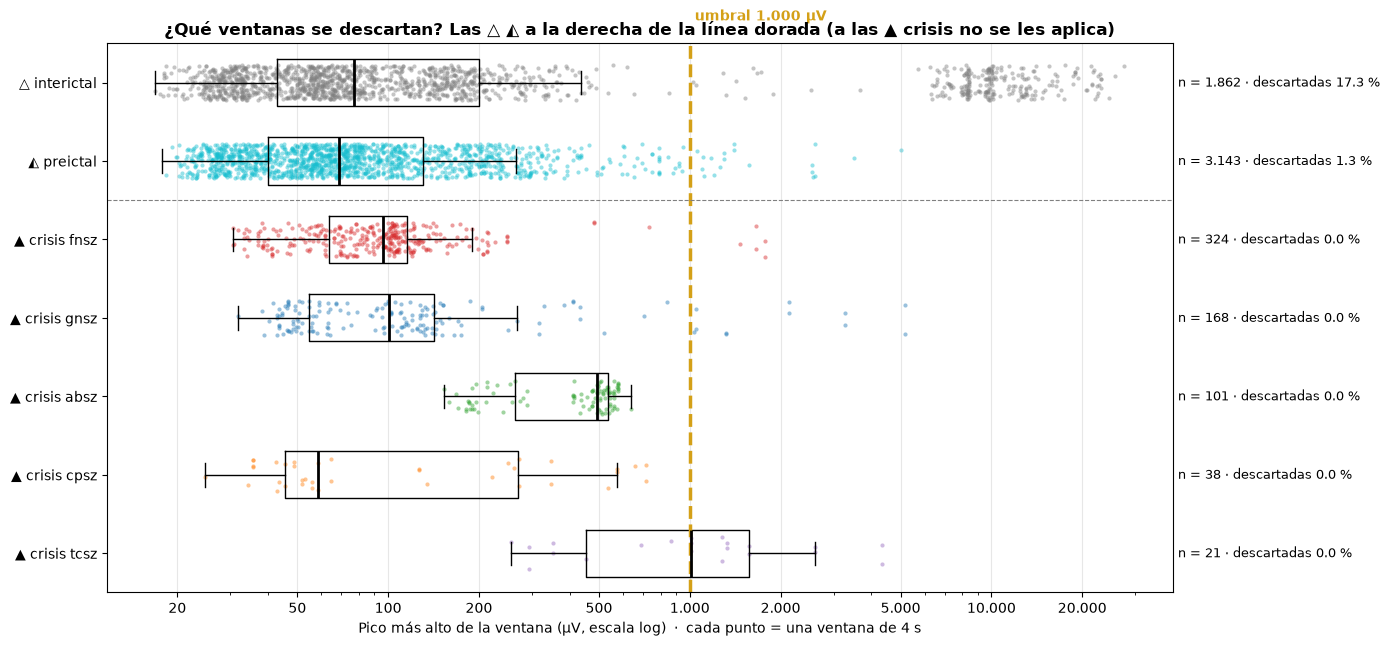

In [8]:
# Figura: picos de las ventanas por clase y tipo, con el umbral
filas_figura = [(con_icono(c), ventanas_df[ventanas_df.clase == c], COLORES_PERIODO[c]) for c in ['interictal', 'preictal']]
ictales = ventanas_df[ventanas_df.clase == 'ictal']           # ya con la columna 'rechazada'
filas_figura += [(f'▲ crisis {tipo}', g, COLORES_ETIQUETA.get(tipo, 'black'))
                 for tipo, g in sorted(ictales.groupby('tipo'), key=lambda par: -len(par[1]))]
MAX_PUNTOS = 1500
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(14, 0.65 * len(filas_figura) + 2))
for y, (nombre, g, color) in enumerate(filas_figura):
    amplitudes = g.amplitud_max_uv
    puntos = amplitudes.sample(min(MAX_PUNTOS, len(amplitudes)), random_state=0)
    ax.scatter(puntos, y + rng.uniform(-0.22, 0.22, len(puntos)), s=9, color=color, alpha=0.45, linewidths=0)
    ax.boxplot(amplitudes, positions=[y], orientation='horizontal', widths=0.6, showfliers=False,
               boxprops=dict(color='black'), medianprops=dict(color='black', lw=2),
               whiskerprops=dict(color='black'), capprops=dict(color='black'))
    descartadas = g.rechazada.mean() * 100 if len(g) else 0
    ax.text(1.005, y, f'n = {numero_legible(len(g))} · descartadas {descartadas:.1f} %',
            transform=ax.get_yaxis_transform(), va='center', fontsize=9)
ax.axvline(umbral_rechazo, color=COLOR_DESTACADO, lw=2.5, ls='--')
ax.text(umbral_rechazo, -0.75, f' umbral {numero_legible(round(umbral_rechazo))} µV', color=COLOR_DESTACADO,
        fontweight='bold', va='bottom')
ax.axhline(1.5, color='gray', lw=0.8, ls='--')
ax.set_yticks(range(len(filas_figura)), [nombre for nombre, _, _ in filas_figura])
ax.invert_yaxis()
ax.set_xscale('log')
eje_log_legible(ax, 'x')
ax.set_xlabel('Pico más alto de la ventana (µV, escala log)  ·  cada punto = una ventana de 4 s')
ax.grid(axis='x', alpha=0.3)
ax.set_title('¿Qué ventanas se descartan? Las △ ◭ a la derecha de la línea dorada (a las ▲ crisis no se les aplica)',
             fontweight='bold')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'rechazo_ventanas.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.1. Qué hace la figura y qué pretende representar

**Qué hace.** Es la misma idea que la figura de calidad de `02_preprocesado`, pero ya con **ventanas de 4 s** (no tramos enteros) y con el **umbral real** dibujado:

- **Filas**: arriba △ interictal y ◭ preictal; debajo de la línea discontinua gris, las ▲ crisis por tipo.
- **Puntos**: cada punto es una ventana, colocada según su pico más alto (escala log). La **caja** marca la mitad central de las ventanas y la raya gruesa, la mediana.
- **Línea dorada**: el umbral de rechazo, calculado en la celda anterior.
- **A la derecha**: cuántas ventanas hay en cada fila y qué porcentaje se descarta (por amplitud o por canales planos).

**Qué pretende representar.** Que el umbral **limpia artefactos sin perder crisis**:

- En **△ ◭**, lo que queda a la derecha de la línea son picos más altos que casi cualquier crisis: artefactos. Se descartan.
- En **▲ crisis**, la línea debería quedar **a la derecha de casi todos los puntos**. Aunque alguno quede a la derecha, a las crisis no se les aplica el rechazo: solo se pierden si tienen canales planos.

**Si algo no cuadra**: si △ ◭ pierden mucho (más de `MAX_PERDIDA_PCT`), o si un tipo de crisis (aparte de 🟪 `tcsz` (🔷)) queda muy a la derecha de la línea, conviene subir `UMBRAL_RECHAZO_UV`. Ojo: que un fichero pierda casi todas sus ventanas puede ser correcto. Por ejemplo, en dos ficheros de 🟢 eval (`aaaaaarq_s014_t009` y `aaaaaarq_s017_t005`) la señal se rompe en todos los canales unos minutos después de la crisis y hasta el final de la grabación (desviación ~2.000 µV, picos ~10.000 µV), así que su tramo △ se descarta casi entero.

In [9]:
def resumen_rechazo(g):
    return pd.Series({'ventanas': len(g),
                      'descartadas por amplitud': int(g.motivo_rechazo.str.contains('amplitud').sum()),
                      'descartadas por canales planos': int(g.motivo_rechazo.str.contains('planos').sum()),
                      '% descartadas': g.rechazada.mean() * 100})
tabla_rechazo = ventanas_df.groupby(['split', 'clase']).apply(resumen_rechazo, include_groups=False).reindex(SPLITS, level=0)
display(Markdown('**Ventanas descartadas por partición y clase:**'))
display(con_separadores(tabla_con_iconos(tabla_rechazo)))

**Ventanas descartadas por partición y clase:**

👀 **Cómo leer la tabla.** Ventanas descartadas por partición y clase, separadas por motivo (amplitud o canales planos). En ▲ ictal solo puede haber descartes por canales planos.

## 6. Cuántas ventanas hay de cada clase

Recuento de las ventanas **que se usarán** (sin las descartadas). Para ◭ preictal se cuentan las del **modelo general** (`en_general`), que es el principal. Arriba de cada barra, el número de ventanas; en el título de cada partición, cuántas △ interictales hay por cada ◭ preictal: es el **desbalance** que `04` tendrá que equilibrar (solo en train).

💾 **Guardado `ventanas_por_clase.csv`** · 186 B · 3 filas × 6 columnas  
*Qué guarda:* una fila por partición: ventanas △ interictales, ◭ preictales (del modelo general y de los modelos de grupo) y ▲ ictales que se usarán, y cuántas interictales hay por cada preictal. *Abajo:* las 3 primeras filas.

,split,△ interictal,preictal (modelo general),preictal (modelo de grupo),▲ ictal,interictal por preictal (general)
0,🔵 train,1277,696,750,422,1.8
1,🟡 dev,263,88,292,136,3.0
2,🟢 eval,0,167,167,94,0.0


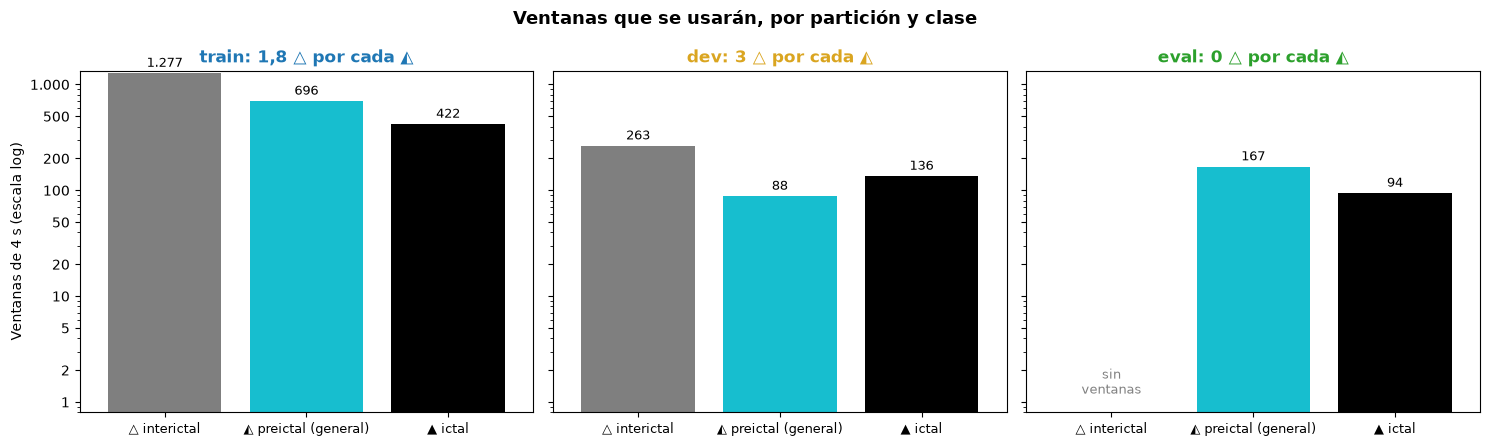

In [10]:
usadas = ventanas_df[~ventanas_df.rechazada]
recuento = pd.DataFrame({
    'interictal': usadas[usadas.clase == 'interictal'].groupby('split').size(),
    'preictal (modelo general)': usadas[(usadas.clase == 'preictal') & usadas.en_general].groupby('split').size(),
    'preictal (modelo de grupo)': usadas[(usadas.clase == 'preictal') & usadas.en_modelo_grupo].groupby('split').size(),
    'ictal': usadas[usadas.clase == 'ictal'].groupby('split').size(),
}).reindex(SPLITS).fillna(0).astype(int)
recuento['interictal por preictal (general)'] = (recuento['interictal'] / recuento['preictal (modelo general)'].replace(0, np.nan)).round(1)
recuento.index.name = 'split'
recuento.to_csv(RUTA_RESULTADOS / 'ventanas_por_clase.csv')
mostrar_fichero(RUTA_RESULTADOS / 'ventanas_por_clase.csv',
                'una fila por partición: ventanas △ interictales, ◭ preictales (del modelo general y de los modelos de grupo) y ▲ ictales que se usarán, y cuántas interictales hay por cada preictal')

clases_fig = [('interictal', '△ interictal', COLORES_PERIODO['interictal']),
              ('preictal (modelo general)', '◭ preictal (general)', COLORES_PERIODO['preictal']),
              ('ictal', '▲ ictal', COLORES_PERIODO['ictal'])]
fig, axes = plt.subplots(1, len(SPLITS), figsize=(15, 4.5), sharey=True)
for ax, s in zip(axes, SPLITS):
    valores = [recuento.loc[s, c] for c, _, _ in clases_fig]
    x = np.arange(len(clases_fig))
    ax.bar(x[np.array(valores) > 0], [v for v in valores if v > 0],
           color=[col for (_, _, col), v in zip(clases_fig, valores) if v > 0])
    for xi, v in zip(x, valores):
        ax.text(xi, v * 1.15 if v > 0 else 1.2, numero_legible(int(v)) if v > 0 else 'sin\nventanas',
                ha='center', fontsize=9, color='black' if v > 0 else 'gray')
    ax.set_xticks(x, [e for _, e, _ in clases_fig])
    ax.set_xlim(-0.6, len(clases_fig) - 0.4)
    ratio = recuento.loc[s, 'interictal por preictal (general)']
    ax.set_title(f'{s}: {numero_legible(ratio) if pd.notna(ratio) else "—"} △ por cada ◭',
                 color=COLORES_SPLIT[s], fontweight='bold')
    ax.set_yscale('log')
    ax.set_ylim(bottom=0.8)
    ax.tick_params(axis='x', labelsize=9)
eje_log_legible(axes[0], 'y')
axes[0].set_ylabel('Ventanas de 4 s (escala log)')
fig.suptitle('Ventanas que se usarán, por partición y clase', fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'ventanas_por_clase.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Crisis que se quedan sin ventanas

Una crisis de menos de 4 s no da ni una ventana completa, así que **no podrá clasificarse** en la Fase 4. La tabla dice, por tipo, cuántas crisis tienen al menos una ventana ▲ ictal y cuántas ventanas da la crisis típica. Si un tipo pierde muchas (las ausencias son cortas), es un argumento para probar ventanas más cortas (2 s) en la Fase 4.

In [11]:
crisis_tramos = tramos[tramos.clase == 'ictal']
con_ventanas = ventanas_df[ventanas_df.clase == 'ictal'].groupby('crisis_id').size()
cobertura = crisis_tramos.assign(ventanas=crisis_tramos.crisis_id.map(con_ventanas).fillna(0)).groupby('tipo').agg(
    crisis=('crisis_id', 'nunique'), duracion_mediana_s=('duracion_s', 'median'),
    crisis_con_ventanas=('ventanas', lambda v: int((v > 0).sum())), ventanas_por_crisis=('ventanas', 'median'))
cobertura['% sin ventanas'] = (100 * (1 - cobertura.crisis_con_ventanas / cobertura.crisis)).round(1)
cobertura = cobertura.sort_values('crisis', ascending=False)
display(con_separadores(tabla_con_iconos(cobertura)))

,crisis,duracion_mediana_s,crisis_con_ventanas,ventanas_por_crisis,% sin ventanas
tipo,,,,,
🟩 absz (🔹),27,"7,2",23,"2,0","14,8"
🟦 gnsz (🔷),14,"20,7",14,"8,5","0,0"
🟥 fnsz (♦️),11,"48,5",11,"23,0","0,0"
🟧 cpsz (♦️),2,"40,1",2,"19,0","0,0"
🟪 tcsz (🔷),1,"45,0",1,"21,0","0,0"


👀 **Cómo leer la tabla.** Una fila por tipo. `% sin ventanas` alto = muchas crisis más cortas que 4 s, que no se podrán clasificar con esta ventana; `ventanas_por_crisis` = cuántas ventanas da la crisis típica.

## 8. Lo que verá el modelo: una ventana de cada clase

Una ventana de 4 s de cada clase (de `FICHERO_EJEMPLO` si tiene; si no, la primera que haya), leída del `.npy` con la **misma función del cargador** (`ventanas_de_senal`) y **normalizada** canal a canal con la normalización robusta (`normalizacion.py`), como hará la Fase 3. Se dibujan los canales de `CANALES_FIGURAS`, uno debajo de otro.

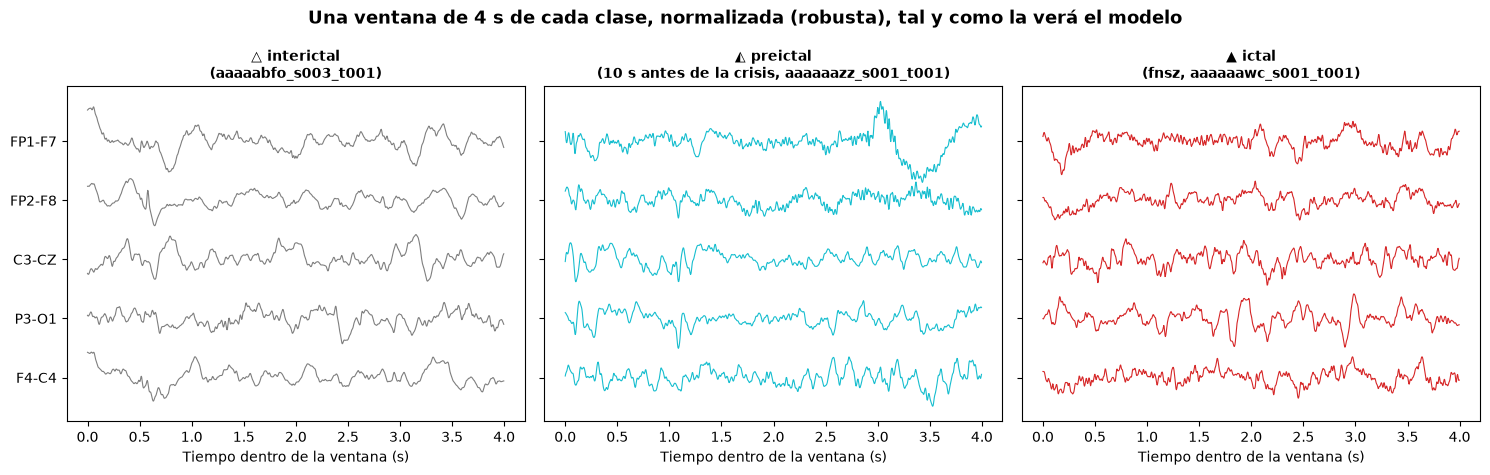

In [12]:
normalizar = NORMALIZACIONES['robusta']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
t = np.arange(TAMANO) / FS_OBJETIVO
for ax, clase in zip(axes, ['interictal', 'preictal', 'ictal']):
    candidatas = usadas[(usadas.clase == clase) & (usadas.file == FICHERO_EJEMPLO)]
    if candidatas.empty:
        candidatas = usadas[usadas.clase == clase]
    if candidatas.empty:
        ax.set_title(f'{con_icono(clase)}: no hay ventanas', fontweight='bold')
        continue
    w = candidatas.iloc[len(candidatas) // 2]
    ventana = normalizar(ventanas_de_senal(cargar_tramo(RUTA_SENALES / w.ruta), TAMANO, [w.muestra_inicio])[0])
    for k, canal in enumerate(CANALES_FIGURAS):
        ax.plot(t, ventana[CANALES_TCP.index(canal)] - 8 * k, color=COLORES_PERIODO[clase] if clase != 'ictal'
                else COLORES_ETIQUETA.get(w.tipo, 'black'), lw=0.8)
    detalle = f'{w.tipo}, ' if clase == 'ictal' else (f'{w.segundos_hasta_crisis:.0f} s antes de la crisis, ' if clase == 'preictal' else '')
    ax.set_title(f'{con_icono(clase)}\n({detalle}{w.file})', fontweight='bold', fontsize=10)
    ax.set_xlabel('Tiempo dentro de la ventana (s)')
axes[0].set_yticks([-8 * k for k in range(len(CANALES_FIGURAS))], CANALES_FIGURAS)
fig.suptitle(f'Una ventana de {VENTANA_S} s de cada clase, normalizada (robusta), tal y como la verá el modelo',
             fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'ejemplo_ventanas.png', dpi=150, bbox_inches='tight')
plt.show()

👀 **Qué mirar.** Tres paneles (△, ◭ y ▲), con la misma escala; cada línea es un canal. Tras normalizar, las tres tienen una amplitud parecida: el modelo tendrá que fijarse en **la forma y el ritmo** de la señal, no en su tamaño. Entre △ y ◭ apenas se ven diferencias a simple vista: es justo lo que tendrá que aprender el modelo.

## 9. Tabla de ventanas → `ventanas.csv`

<div style="background:#fff6d8; color:#1a1a1a; border:2px solid #d4a017; border-radius:8px; padding:10px 14px">
<span style="color:#1a1a1a">🏆 <b style="color:#1a1a1a">El resultado de este notebook.</b> <b style="color:#1a1a1a">ventanas.csv</b> es el <b style="color:#1a1a1a">índice de todas las ventanas</b>: de qué .npy sale cada una, en qué muestra empieza, su clase, a qué modelos pertenece y si se descarta. Con él, la Fase 3 lee cada ventana directamente de la señal preprocesada.</span>
</div>

Antes de guardar se comprueba que:

1. Toda ventana cabe **dentro de su tramo**.
2. Ninguna ◭ preictal del modelo general se mete en el **SPH** ni empieza antes del **umbral**.
3. Ninguna ▲ ictal está descartada por **amplitud** (a las crisis no se les aplica).

In [13]:
n_tramo = ventanas_df.id_tramo.map(tramos.set_index('id_tramo').n_muestras)
fuera = (ventanas_df.muestra_inicio < 0) | (ventanas_df.muestra_inicio + TAMANO > n_tramo)
print(f'1. Ventanas que no caben en su tramo (debe ser 0): {int(fuera.sum())}')
general_pre = ventanas_df[(ventanas_df.clase == 'preictal') & ventanas_df.en_general]
mal_general = (general_pre.segundos_hasta_crisis < SPH_POR_DEFECTO_S - 1e-3) | \
              (general_pre.segundos_hasta_crisis + VENTANA_S > UMBRAL_LEADIN_POR_DEFECTO_S + 1e-3)
print(f'2. ◭ Ventanas del modelo general fuera de su preictal (debe ser 0): {int(mal_general.sum())}')
ictal_amplitud = ((ventanas_df.clase == 'ictal') & ventanas_df.motivo_rechazo.str.contains('amplitud')).sum()
print(f'3. ▲ Ventanas ictales descartadas por amplitud (debe ser 0): {int(ictal_amplitud)}')
assert fuera.sum() == 0 and mal_general.sum() == 0 and ictal_amplitud == 0, '🔴 Alguna comprobación ha fallado.'

COLUMNAS = ['clase', 'split', 'patient', 'file', 'tipo', 'grupo', 'crisis_id', 'id_tramo', 'ruta', 'muestra_inicio',
            'inicio_s', 'fin_s', 'segundos_hasta_crisis', *COLUMNAS_MODELO, 'amplitud_max_uv', 'canales_planos',
            'rechazada', 'motivo_rechazo']
ventanas_df = ventanas_df[COLUMNAS]
ventanas_df.to_csv(RUTA_RESULTADOS / 'ventanas.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'ventanas.csv',
                'una fila por ventana de 4 s: su clase y paciente, de qué .npy sale (ruta) y en qué muestra empieza, cuándo es dentro del EDF, a qué modelos pertenece (columnas en_…), su calidad y si se descarta')

DESCRIPCION_COLUMNAS = {
    'clase': '△ interictal, ◭ preictal o ▲ ictal', 'split': 'Partición', 'patient': 'Paciente', 'file': 'Fichero EDF',
    'tipo': 'Tipo de crisis (◭ y ▲)', 'grupo': 'Grupo de inicio (◭ y ▲)', 'crisis_id': 'Crisis a la que pertenece (◭ y ▲)',
    'id_tramo': 'Tramo del que sale (senales.csv)', 'ruta': 'Su .npy, dentro de senales/',
    'muestra_inicio': f'Muestra del .npy en la que empieza (la ventana son {TAMANO} muestras)',
    'inicio_s': 'Inicio dentro del EDF (s)', 'fin_s': 'Fin dentro del EDF (s)',
    'segundos_hasta_crisis': '◭ Segundos desde el final de la ventana hasta el inicio de la crisis',
    **{c: 'Vale para ese modelo (ver sección 4)' for c in COLUMNAS_MODELO},
    'amplitud_max_uv': 'Pico más alto de la ventana (µV)', 'canales_planos': 'Canales válidos casi quietos',
    'rechazada': 'Se descarta (sección 5)', 'motivo_rechazo': 'Por qué: amplitud, canales planos o los dos',
}
leido = pd.read_csv(RUTA_RESULTADOS / 'ventanas.csv')
columnas_csv = pd.DataFrame({'tipo de dato': leido.dtypes.astype(str),
                             'qué es': [DESCRIPCION_COLUMNAS.get(c, '') for c in leido.columns]})
columnas_csv.index.name = 'columna'
mostrar_destacado('ventanas.csv: el índice de todas las ventanas',
                  f'<b>{numero_legible(len(leido))} ventanas × {leido.shape[1]} columnas</b> · '
                  f'{numero_legible(int((~leido.rechazada).sum()))} se usan y {numero_legible(int(leido.rechazada.sum()))} se descartan',
                  '<b>Qué significa cada columna</b>', columnas_csv)

1. Ventanas que no caben en su tramo (debe ser 0): 0
2. ◭ Ventanas del modelo general fuera de su preictal (debe ser 0): 0
3. ▲ Ventanas ictales descartadas por amplitud (debe ser 0): 0


💾 **Guardado `ventanas.csv`** · 1,5 MB · 5.657 filas × 28 columnas  
*Qué guarda:* una fila por ventana de 4 s: su clase y paciente, de qué .npy sale (ruta) y en qué muestra empieza, cuándo es dentro del EDF, a qué modelos pertenece (columnas en_…), su calidad y si se descarta. *Abajo:* las 5 primeras filas.

,clase,split,patient,file,tipo,grupo,crisis_id,id_tramo,ruta,muestra_inicio,...,en_umbral_7min,en_umbral_10min,en_umbral_15min,en_modelo_grupo,en_test_comun,en_clasificacion,amplitud_max_uv,canales_planos,rechazada,motivo_rechazo
0,◭ preictal,🔵 train,aaaaaacz,aaaaaacz_s006_t000,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,aaaaaacz_s006_t000_preictal_000409636,train/preictal/aaaaaacz_s006_t000_preictal_000...,33894,...,False,True,False,False,False,False,92.1875,0,False,NaN
1,◭ preictal,🔵 train,aaaaaacz,aaaaaacz_s006_t000,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,aaaaaacz_s006_t000_preictal_000409636,train/preictal/aaaaaacz_s006_t000_preictal_000...,34406,...,False,True,False,False,False,False,92.1875,0,False,NaN
2,◭ preictal,🔵 train,aaaaaacz,aaaaaacz_s006_t000,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,aaaaaacz_s006_t000_preictal_000409636,train/preictal/aaaaaacz_s006_t000_preictal_000...,34918,...,False,True,False,False,False,False,90.6875,0,False,NaN
3,◭ preictal,🔵 train,aaaaaacz,aaaaaacz_s006_t000,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,aaaaaacz_s006_t000_preictal_000409636,train/preictal/aaaaaacz_s006_t000_preictal_000...,35430,...,False,True,False,False,False,False,90.6875,0,False,NaN
4,◭ preictal,🔵 train,aaaaaacz,aaaaaacz_s006_t000,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,aaaaaacz_s006_t000_preictal_000409636,train/preictal/aaaaaacz_s006_t000_preictal_000...,35942,...,False,True,False,False,False,False,92.5000,0,False,NaN


,tipo de dato,qué es
columna,,
clase,str,"△ interictal, ◭ preictal o ▲ ictal"
split,str,Partición
patient,str,Paciente
file,str,Fichero EDF
tipo,str,Tipo de crisis (◭ y ▲)
grupo,str,Grupo de inicio (◭ y ▲)
crisis_id,str,Crisis a la que pertenece (◭ y ▲)
id_tramo,str,Tramo del que sale (senales.csv)
ruta,str,"Su .npy, dentro de senales/"


## 10. Resumen → `summary.txt`

Los datos y las tablas principales, en texto, para consultarlos sin abrir el notebook.

In [14]:
datos = [
    f'Ventanas: {config["fecha"]}' + ('  ·  MODO PRUEBA (preprocesado incompleto)' if modo_prueba else ''),
    f'Ventana de {VENTANA_S} s ({TAMANO} muestras) · solape: △ {SOLAPE_POR_CLASE["interictal"]:.0%}, '
    f'◭ {SOLAPE_POR_CLASE["preictal"]:.0%}, ▲ {SOLAPE_POR_CLASE["ictal"]:.0%}',
    f'Tramos con señal: {numero_legible(len(tramos))} · ventanas: {numero_legible(len(ventanas_df))} '
    f'({numero_legible(int((~ventanas_df.rechazada).sum()))} se usan)',
    f'Umbral de rechazo: {numero_legible(round(umbral_rechazo))} µV ({origen_umbral}), aplicado a {", ".join(RECHAZO_EN_CLASES)}',
]
tablas_resumen = {
    'Ventanas que se usarán, por partición': tabla_con_iconos(recuento),
    '◭ Ventanas preictales de cada modelo': tabla_con_iconos(por_modelo),
    'Picos de las ventanas ▲ ictales por tipo (µV)': tabla_con_iconos(umbral_por_tipo.round(1)),
    'Ventanas descartadas': tabla_con_iconos(tabla_rechazo.round(1)),
    'Crisis que se quedan sin ventanas': tabla_con_iconos(cobertura),
}
texto = ('=== Ventanas (Fase 2 · 03) ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen de las ventanas en texto, para consultarlo sin abrir el notebook')

display(Markdown('\n'.join(f'- {d}' for d in datos)))
for titulo, tabla in tablas_resumen.items():
    display(Markdown(f'#### {titulo}'))
    display(con_separadores(tabla))

💾 **Guardado `summary.txt`** · 4,7 KB · 57 líneas  
*Qué guarda:* el resumen de las ventanas en texto, para consultarlo sin abrir el notebook. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== Ventanas (Fase 2 · 03) ===
2,Ventanas: 2026-10-29 16:06 · MODO PRUEBA (preprocesado incompleto)
3,"Ventana de 4 s (1024 muestras) · solape: △ 0%, ◭ 50%, ▲ 50%"
4,Tramos con señal: 103 · ventanas: 5.657 (5.294 se usan)
5,"Umbral de rechazo: 1.000 µV (valor fijo, común a △ y ◭, comprobado con las crisis de cada tipo), aplicado a interictal, preictal"


- Ventanas: 2026-10-29 16:06  ·  MODO PRUEBA (preprocesado incompleto)
- Ventana de 4 s (1024 muestras) · solape: △ 0%, ◭ 50%, ▲ 50%
- Tramos con señal: 103 · ventanas: 5.657 (5.294 se usan)
- Umbral de rechazo: 1.000 µV (valor fijo, común a △ y ◭, comprobado con las crisis de cada tipo), aplicado a interictal, preictal

#### Ventanas que se usarán, por partición

,△ interictal,preictal (modelo general),preictal (modelo de grupo),▲ ictal,interictal por preictal (general)
split,,,,,
🔵 train,1.277,696,750,422,"1,8"
🟡 dev,263,88,292,136,"3,0"
🟢 eval,0,167,167,94,"0,0"


#### ◭ Ventanas preictales de cada modelo

... (2 outputs left out)

,crisis,ventanas,mediana_uv,p95_uv,p99_uv,maximo_uv,pct_por_encima,cuenta_en_la_comprobacion
tipo,,,,,,,,
🟩 absz (🔹),23,101,"492,0","578,0","579,5","637,5","0,0",True
🟦 gnsz (🔷),14,168,"100,9","1.052,0","3.900,3","5.188,0","6,5",True
🟥 fnsz (♦️),11,324,"96,3","212,7","1.610,0","1.780,0","1,5",True
🟧 cpsz (♦️),2,38,"58,8","668,3","715,5","715,5","0,0",True
🟪 tcsz (🔷),1,21,"1.012,5","4.328,0","4.328,0","4.328,0","61,9",False


#### Ventanas descartadas

#### Crisis que se quedan sin ventanas

,crisis,duracion_mediana_s,crisis_con_ventanas,ventanas_por_crisis,% sin ventanas
tipo,,,,,
🟩 absz (🔹),27,"7,2",23,"2,0","14,8"
🟦 gnsz (🔷),14,"20,7",14,"8,5","0,0"
🟥 fnsz (♦️),11,"48,5",11,"23,0","0,0"
🟧 cpsz (♦️),2,"40,1",2,"19,0","0,0"
🟪 tcsz (🔷),1,"45,0",1,"21,0","0,0"


## 11. Conclusiones

**1. La señal ya está en la unidad que verá el modelo**
- Ventanas de **4 s** (22 × 1.024), en el rango que recomienda la literatura para no diluir las ausencias. ◭ y ▲ con 50 % de solape para aprovechar la poca señal que hay.

**2. Cada ventana sabe a qué modelo pertenece**
- Modelo general, comparación de umbrales, modelos de grupo, test común y clasificación de tipos salen de **la misma tabla**, con una columna `en_...` por modelo. La Fase 3 solo tiene que filtrar.

**3. El rechazo es el mismo para todas las clases y se ha comprobado con datos**
- Umbral fijo de 1.000 µV, común a △ y ◭ (para que el modelo no aprenda un atajo de amplitud), comprobado con las crisis de cada tipo (sin 🟪 `tcsz` (🔷)). Las crisis no se pierden por amplitud.

**4. La señal no se duplica**
- `ventanas.csv` es un índice. El cargador de la Fase 3 leerá cada ventana del `.npy` y la normalizará al vuelo, igual que la demo.

> ✏️ Las cifras de esta ejecución (ventanas por clase, umbral, descartadas, crisis sin ventanas) están en las secciones 4 a 7 y en `summary.txt`. En modo prueba no son representativas.

## 12. Archivos generados y siguiente paso

En `outputs/fase_02/03_ventanas/`:

- `configuracion.json`: tamaño de ventana, solape, umbrales de los modelos, criterios de rechazo, versiones y fecha.
- `ventanas.csv`: **una fila por ventana**: de dónde sale, a qué modelos pertenece y su calidad. Es la entrada de `04_particiones_y_balanceo`.
- `umbral_rechazo_por_tipo.csv`: picos de las ventanas ▲ ictales por tipo (de aquí sale el umbral).
- `ventanas_por_clase.csv`: ventanas que se usarán por partición y clase.
- `summary.txt`: tablas resumen (con iconos).
- `figuras/`: `corte_ventanas.png`, `rechazo_ventanas.png`, `ventanas_por_clase.png`, `ejemplo_ventanas.png`.

**Siguiente paso**: `04_particiones_y_balanceo.ipynb`, que reparte las ventanas por paciente, deja un máximo de horas de △ interictal por paciente y equilibra las clases solo en train.